# 14. Write a python program to apply spatial sharpening filters (Laplacian, Gradient masks).

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [45]:
img = cv2.imread("image.jpeg", cv2.IMREAD_GRAYSCALE)

In [46]:
laplacian_mask = np.array([
    [0, -1, 0],
    [-1, 4, -1],
    [0, -1, 0]
])

sobel_x_mask = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

sobel_y_mask = np.array([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1]
])

In [47]:
laplacian_img = np.zeros(img.shape, dtype=np.float32)
sobel_x_img = np.zeros(img.shape, dtype=np.float32)
sobel_y_img = np.zeros(img.shape, dtype=np.float32)

In [ ]:
for i in range(1, img.shape[0] - 1):
    for j in range(1, img.shape[1] - 1):
        matrix = img[i-1: i+2, j-1: j+2]
        laplacian_img[i][j] = np.sum(matrix * laplacian_mask)
        sobel_x_img[i][j] = np.sum(matrix * sobel_x_mask)
        sobel_y_img[i][j] = np.sum(matrix * sobel_y_mask)

# Laplacian sharpening
laplacian_sharp = img.astype(np.float32) + laplacian_img
laplacian_sharp = np.clip(laplacian_sharp, 0, 255).astype(np.uint8)
# Gradient calculation
gradient_img = np.abs(sobel_x_img) + np.abs(sobel_y_img)
gradient_img = np.clip(gradient_img, 0, 255).astype(np.uint8)

In [49]:
# Gradient sharpening
gradient_sharp = img.astype(np.float32) + gradient_img
gradient_sharp = np.clip(gradient_sharp, 0, 255).astype(np.uint8)

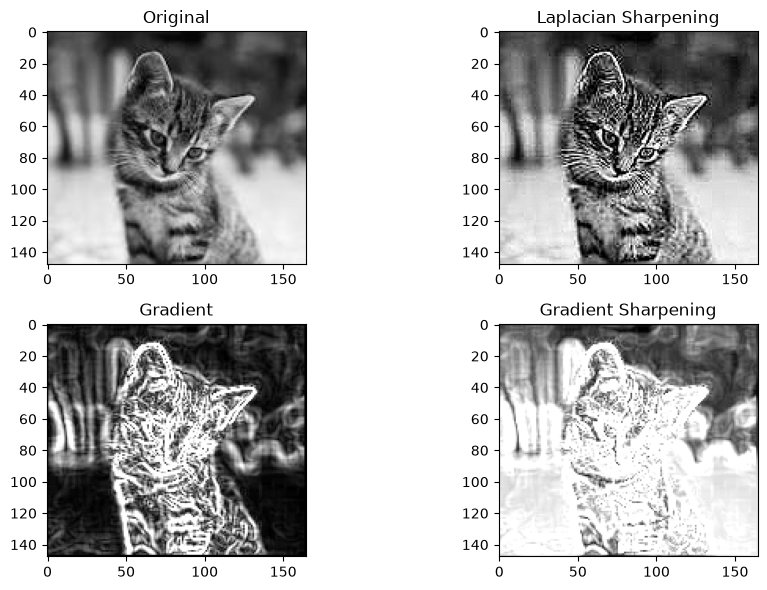

In [51]:
# Display results
plt.figure(figsize=(10,6))

plt.subplot(2,2,1)
plt.imshow(img, cmap="gray")
plt.title("Original")

plt.subplot(2,2,2)
plt.imshow(laplacian_sharp, cmap="gray")
plt.title("Laplacian Sharpening")

plt.subplot(2,2,3)
plt.imshow(gradient_img, cmap="gray")
plt.title("Gradient")

plt.subplot(2,2,4)
plt.imshow(gradient_sharp, cmap="gray")
plt.title("Gradient Sharpening")

plt.tight_layout()
plt.show()